# 05 – Figures and tables for the report (classification)
Code for every step of the dataset evaluation report. The report itself (`exercise_project_1_report_classification.ipynb`) contains only text and figures, like the lecture examples. Written with AI assistance – see the AI disclosure in the report.

In [ ]:
# ---- Setup: imports, data loading, datatype fixes ----
import sys, warnings

warnings.filterwarnings("ignore")
sys.path.append("../../")  # helper.py and report_tools.py live in project_1/
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
from helper import *
from report_tools import *

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

TARGET = "Stress_Level"
ORDER = ["Low", "Medium", "High", "Very High"]  # natural order of the classes
raw = pd.read_csv(
    "../../data/student_mental_health/student_social_media_and_mental_health_impact.csv"
)
df = raw.copy()
df[TARGET] = pd.Categorical(
    df[TARGET], categories=ORDER, ordered=True
)  # text -> ordered category
y_code = df[TARGET].cat.codes  # 0=Low ... 3=Very High (for correlations/models)
num_cols, cat_cols = split_columns(df, TARGET)
PALETTE = dict(zip(ORDER, ["#1a9850", "#a6d96a", "#fdae61", "#d73027"]))
print(
    df.shape,
    "| numeric features:",
    len(num_cols),
    "| categorical features:",
    len(cat_cols),
)

(5000, 13) | numeric features: 7 | categorical features: 5


## 1a) Datatypes

In [ ]:
# Step 1a: datatypes before and after
display(
    pd.DataFrame(
        {
            "raw dtype": raw.dtypes.astype(str),
            "fixed dtype": df.dtypes.astype(str),
            "distinct values": raw.nunique(),
            "example": raw.iloc[0].astype(str),
        }
    )
)

,raw dtype,fixed dtype,distinct values,example
Age,int64,int64,7,21
Gender,str,str,2,Male
Country,str,str,111,Other
Academic_Level,str,str,3,Undergraduate
Most_Used_Platform,str,str,12,Facebook
Purpose_Of_Use,str,str,4,Networking
Avg_Daily_Usage_Hours,float64,float64,79,4.0
Daily_Unlocks,int64,int64,200,134
Study_Hours,float64,float64,76,4.5
Physical_Activity_Hours,float64,float64,44,2.2


## 1b) Shape

In [ ]:
# Step 1b: shape before/after one-hot encoding, rows per class
n_rows, n_cols = df.shape
X_wide = pd.get_dummies(df.drop(columns=TARGET), dtype=float)
print(f"Rows: {n_rows} | columns: {n_cols} (1 target + {n_cols - 1} features)")
print(
    f"After one-hot encoding: {X_wide.shape[1]} feature columns, of which Country = {df['Country'].nunique()}"
)
print(
    f"Rows per raw feature: {n_rows / (n_cols - 1):.0f} | rows per one-hot column: {n_rows / X_wide.shape[1]:.0f}"
)
print("Rows per class:", df[TARGET].value_counts().reindex(ORDER).to_dict())

Rows: 5000 | columns: 13 (1 target + 12 features)
After one-hot encoding: 139 feature columns, of which Country = 111
Rows per raw feature: 417 | rows per one-hot column: 36
Rows per class: {'Low': 644, 'Medium': 1295, 'High': 1440, 'Very High': 1621}


## 1c) Missing values, duplicates, zeros, impossible values

In [ ]:
# Step 1c-1: missing values and duplicates
print("Missing cells in the whole table:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)))
feats = [c for c in df.columns if c != TARGET]
same_x = df[df.duplicated(feats, keep=False)]
print(
    "Rows with identical features:",
    len(same_x),
    "| of those with conflicting labels:",
    int(same_x.groupby(feats, observed=True)[TARGET].nunique().gt(1).sum()),
)

Missing cells in the whole table: 0
Exact duplicate rows: 2


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
886,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
2405,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
1870,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5
2463,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5


Rows with identical features: 4 | of those with conflicting labels: 0


,zeros,negatives,min,max
Age,0,0,18.0,24.0
Avg_Daily_Usage_Hours,0,0,1.0,8.8
Daily_Unlocks,0,0,62.0,273.0
Study_Hours,0,0,0.3,8.3
Physical_Activity_Hours,13,10,-0.4,4.1
Sleep_Hours_Per_Night,0,0,3.6,9.9
Mental_Health_Score,0,0,3.6,9.4


,Physical_Activity_Hours,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Stress_Level
2277,-0.1,6.8,4.7,Very High
2923,-0.1,7.9,5.8,Very High
3056,-0.3,7.8,5.7,Very High
3422,-0.1,8.2,5.8,Very High
3882,-0.2,5.5,5.1,Very High
4058,-0.1,5.8,7.4,High
4243,-0.4,5.6,5.0,Very High
4406,-0.3,7.2,4.5,Very High
4522,-0.2,8.1,5.7,Very High
4771,-0.2,7.6,5.2,Very High


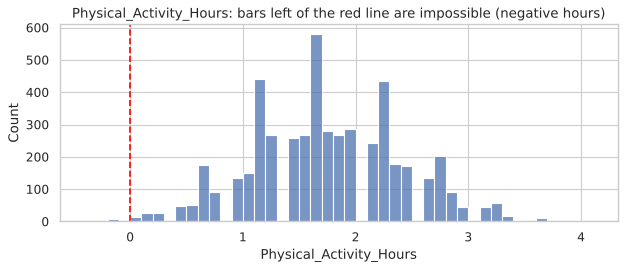

In [ ]:
# Step 1c-2: zeros, negatives and impossible values
display(
    pd.DataFrame(
        {
            "zeros": (df[num_cols] == 0).sum(),
            "negatives": (df[num_cols] < 0).sum(),
            "min": df[num_cols].min(),
            "max": df[num_cols].max(),
        }
    )
)
neg = df["Physical_Activity_Hours"] < 0
display(
    df.loc[
        neg,
        [
            "Physical_Activity_Hours",
            "Avg_Daily_Usage_Hours",
            "Sleep_Hours_Per_Night",
            TARGET,
        ],
    ]
)
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.histplot(df["Physical_Activity_Hours"], bins=45, ax=ax)
ax.axvline(0, color="red", ls="--")
ax.set_title(
    "Physical_Activity_Hours: bars left of the red line are impossible (negative hours)"
)
plt.show()

In [ ]:
# Step 1c-3: common-sense checks
tracked = df[
    [
        "Avg_Daily_Usage_Hours",
        "Study_Hours",
        "Sleep_Hours_Per_Night",
        "Physical_Activity_Hours",
    ]
].sum(axis=1)
print(
    f"Tracked hours per day: min {tracked.min():.1f}, max {tracked.max():.1f}, rows over 24 h: {(tracked > 24).sum()}"
)
display(pd.crosstab(df["Academic_Level"], df["Age"]))
print(
    "Text values with leading/trailing spaces:",
    {c: int((df[c] != df[c].str.strip()).sum()) for c in cat_cols},
)
print(
    "Decimals used in the float columns:",
    {
        c: int(df[c].astype(str).str.split(".").str[-1].str.len().max())
        for c in df.select_dtypes("float").columns
    },
)

Tracked hours per day: min 12.1, max 22.1, rows over 24 h: 0


Age,18,19,20,21,22,23,24
Academic_Level,,,,,,,
Graduate,0,0,0,0,0,496,422
High School,450,0,0,0,0,0,0
Undergraduate,0,906,883,947,896,0,0


Text values with leading/trailing spaces: {'Gender': 0, 'Country': 0, 'Academic_Level': 0, 'Most_Used_Platform': 0, 'Purpose_Of_Use': 0}
Decimals used in the float columns: {'Avg_Daily_Usage_Hours': 1, 'Study_Hours': 1, 'Physical_Activity_Hours': 1, 'Sleep_Hours_Per_Night': 1, 'Mental_Health_Score': 1}


## 1d) Alerts from big-picture tools

In [ ]:
# Step 1d: big-picture tools
alerts = try_ydata_profile(
    df,
    "Student social media & mental health - preliminary EDA",
    "../../reports/student_ydata_profile.html",
)
if alerts is not None:
    display(alerts)
try_sweetviz(
    df.assign(**{TARGET: y_code}), TARGET, "../../reports/student_sweetviz.html"
)  # SweetViz needs a numeric/bool target

ydata-profiling could not be imported: ModuleNotFoundError: No module named 'ydata_profiling'
If the message mentions pkg_resources, run:  python -m pip install "setuptools<81"
SweetViz skipped: ModuleNotFoundError: No module named 'sweetviz'


In [8]:
yd = ydata_style_alerts(df.assign(**{TARGET: df[TARGET].astype(str)}))
display(yd)

,column,alert,detail
0,<whole table>,DUPLICATES,2 duplicate rows
1,Country,HIGH CARDINALITY,111 distinct values
2,Avg_Daily_Usage_Hours,HIGH CORRELATION,with Daily_Unlocks (Spearman 0.96)
3,Most_Used_Platform,HIGH CORRELATION,with Purpose_Of_Use (Cramer's V 0.95)


In [ ]:
DF_AV, AV_DIR = df, "../../reports/autoviz_student"

try:
    from autoviz.AutoViz_Class import AutoViz_Class

    AutoViz_Class().AutoViz(
        "",
        dfte=DF_AV,
        depVar=TARGET,
        chart_format="png",
        save_plot_dir=AV_DIR,
        verbose=0,
    )
except Exception as e:
    print(f"AutoViz skipped: {type(e).__name__}: {e}")

AutoViz skipped: ModuleNotFoundError: No module named 'autoviz'


## 2a) Distributions and imbalances

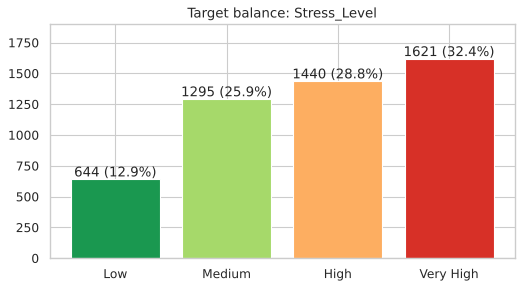

Class shares: {'Low': 12.9, 'Medium': 25.9, 'High': 28.8, 'Very High': 32.4}
Imbalance ratio largest/smallest: 2.52 | ydata imbalance score: 0.035 (alert above 0.5)


In [ ]:
# Step 2a-1: target balance
counts = df[TARGET].value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(ORDER, counts.values, color=[PALETTE[c] for c in ORDER])
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, f"{v} ({v / len(df):.1%})", ha="center")
ax.set_title("Target balance: Stress_Level")
ax.set_ylim(0, 1900)
plt.show()
p = counts / counts.sum()
print("Class shares:", (counts / len(df) * 100).round(1).to_dict())
print(
    f"Imbalance ratio largest/smallest: {counts.max() / counts.min():.2f} | "
    f"ydata imbalance score: {1 - (-(p * np.log2(p)).sum() / np.log2(len(p))):.3f} (alert above 0.5)"
)

,skew,excess_kurtosis,verdict,Shapiro p (n=500)
Study_Hours,0.436,-0.727,roughly symmetric,0.0000
Mental_Health_Score,0.207,-0.803,roughly symmetric,0.0000
Age,0.155,-0.913,roughly symmetric,0.0000
Sleep_Hours_Per_Night,0.124,-0.879,roughly symmetric,0.0001
Physical_Activity_Hours,0.040,-0.226,roughly symmetric,0.1491
Avg_Daily_Usage_Hours,0.006,-0.768,roughly symmetric,0.0000
Daily_Unlocks,0.002,-0.709,roughly symmetric,0.0013


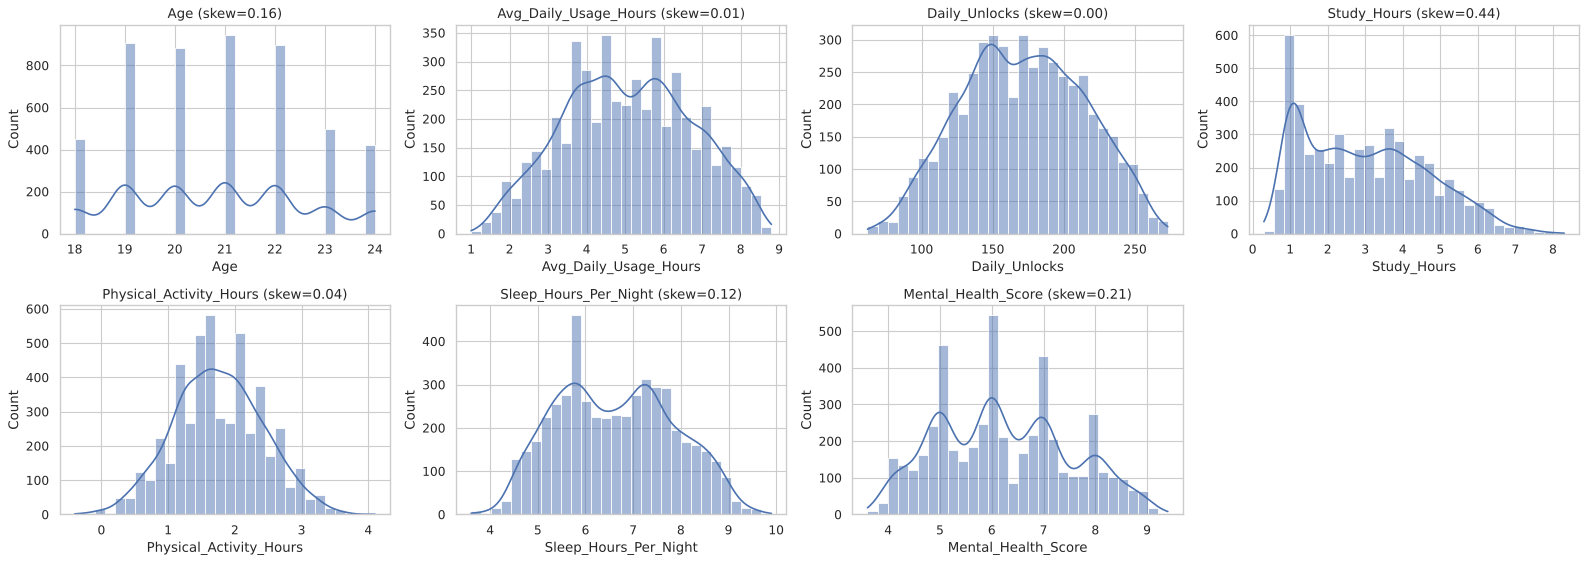

In [ ]:
# Step 2a-2: numeric features - shape, skew, kurtosis, normality
display(
    skew_kurt_table(df, num_cols).join(
        pd.Series(
            {
                c: stats.shapiro(df[c].sample(500, random_state=0)).pvalue
                for c in num_cols
            },
            name="Shapiro p (n=500)",
        ).round(4)
    )
)
hist_grid(df, num_cols, ncols=4)

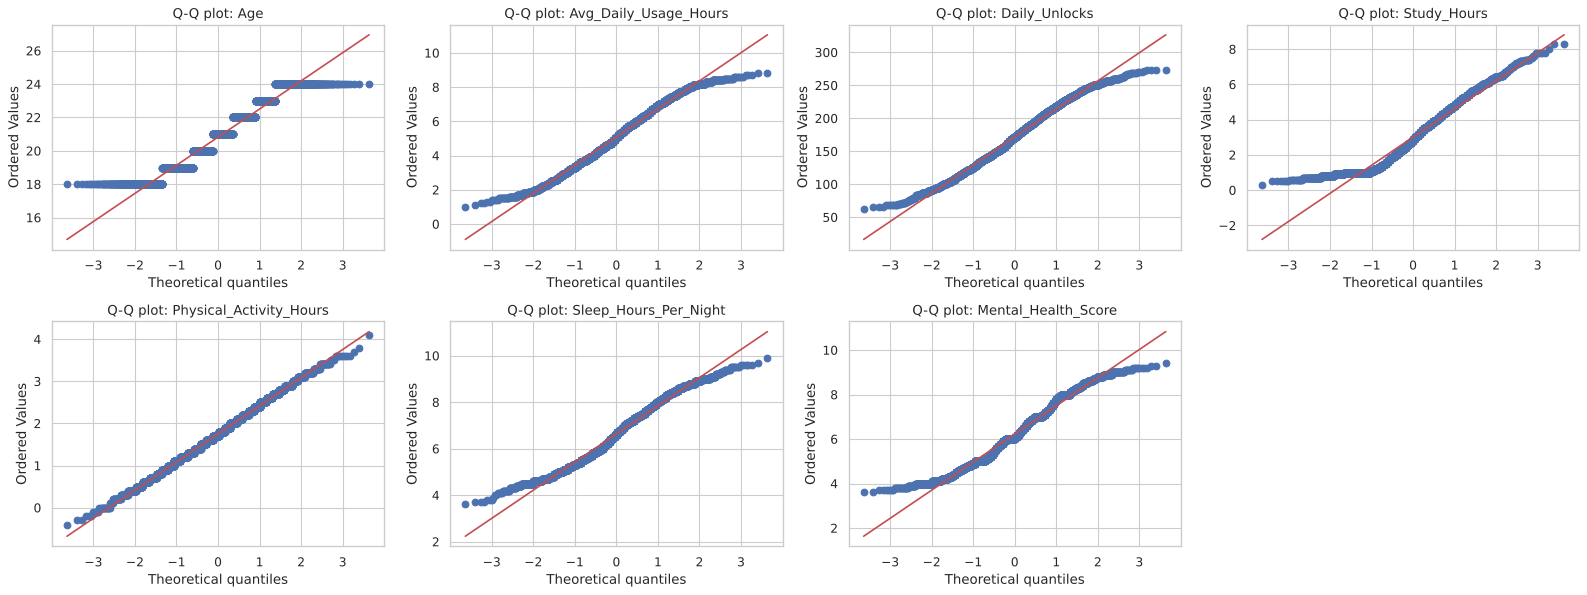

In [12]:
qq_grid(df, num_cols, ncols=4)

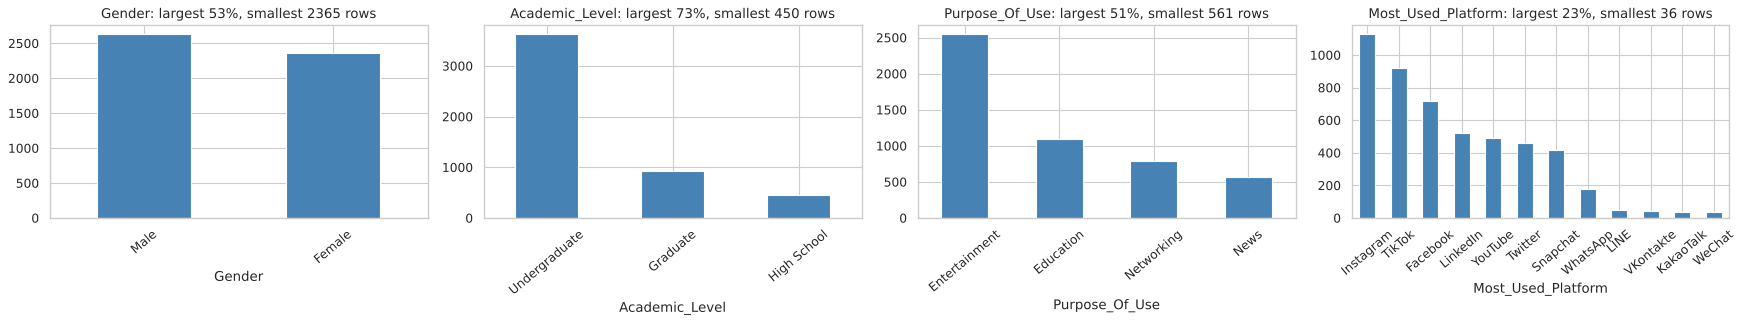

In [ ]:
# Step 2a-3: categorical balance
fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
for ax, col in zip(
    axes, ["Gender", "Academic_Level", "Purpose_Of_Use", "Most_Used_Platform"]
):
    vc = df[col].value_counts()
    vc.plot.bar(ax=ax, color="steelblue", rot=40)
    ax.set_title(
        f"{col}: largest {vc.iloc[0] / len(df):.0%}, smallest {vc.iloc[-1]} rows"
    )
plt.tight_layout()
plt.show()

## 2b) Multicollinearity and redundancy

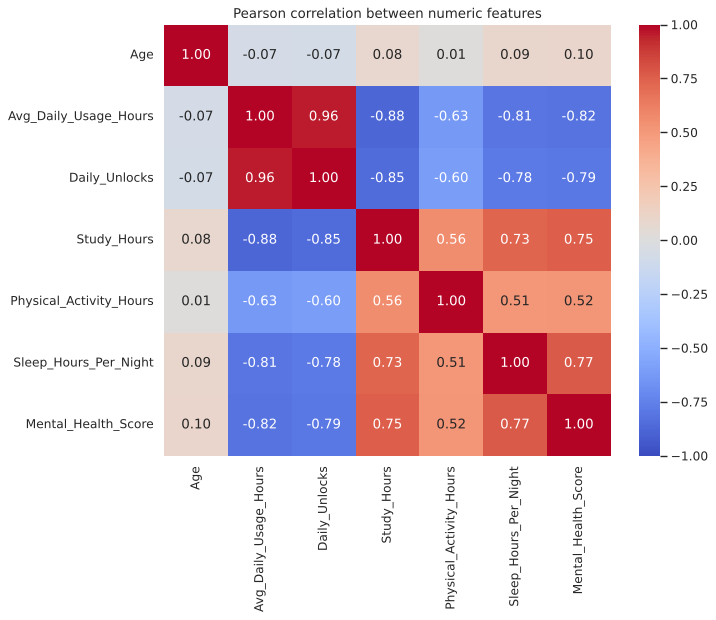

,VIF,R2 from the other features
Avg_Daily_Usage_Hours,17.78,0.944
Daily_Unlocks,12.91,0.923
Study_Hours,4.49,0.777
Mental_Health_Score,3.38,0.704
Sleep_Hours_Per_Night,3.21,0.688
Physical_Activity_Hours,1.65,0.393
Age,1.02,0.015


,feature_1,feature_2,abs_corr
0,Avg_Daily_Usage_Hours,Daily_Unlocks,0.960187
1,Avg_Daily_Usage_Hours,Study_Hours,0.878645
2,Daily_Unlocks,Study_Hours,0.853397
3,Avg_Daily_Usage_Hours,Mental_Health_Score,0.816453
4,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,0.808388


In [ ]:
# Step 2b-1: correlation, VIF and "how well can each feature be predicted from the others"
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
)
ax.set_title("Pearson correlation between numeric features")
plt.show()
from sklearn.linear_model import LinearRegression

r2_others = {
    c: LinearRegression()
    .fit(df[[o for o in num_cols if o != c]], df[c])
    .score(df[[o for o in num_cols if o != c]], df[c])
    for c in num_cols
}
display(
    vif_table(df, num_cols).join(
        pd.Series(r2_others, name="R2 from the other features").round(3)
    )
)
display(high_corr_pairs(df, num_cols, 0.8))

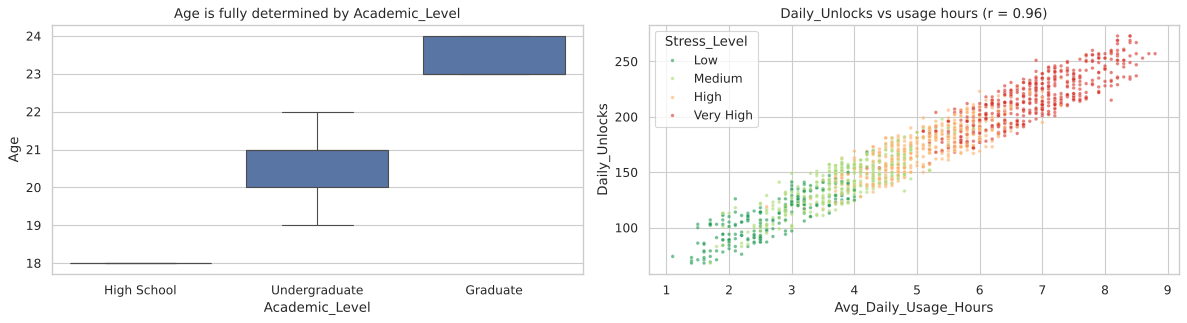

Purpose_Of_Use,Education,Entertainment,Networking,News
Most_Used_Platform,,,,
Facebook,0,0,719,0
Instagram,0,1130,0,0
KakaoTalk,5,11,10,10
LINE,15,13,10,12
LinkedIn,523,0,0,0
Snapchat,0,420,0,0
TikTok,0,918,0,0
Twitter,0,0,0,462
VKontakte,6,14,9,11


Students on platforms with a MIXED purpose: 337 | on the 4 tiny platforms: 162


In [ ]:
# Step 2b-2: Age vs Academic_Level, Daily_Unlocks vs usage
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.boxplot(
    data=df,
    x="Academic_Level",
    y="Age",
    ax=ax[0],
    order=["High School", "Undergraduate", "Graduate"],
)
ax[0].set_title("Age is fully determined by Academic_Level")
sns.scatterplot(
    data=df.sample(1500, random_state=0),
    x="Avg_Daily_Usage_Hours",
    y="Daily_Unlocks",
    hue=TARGET,
    hue_order=ORDER,
    palette=PALETTE,
    s=10,
    alpha=0.6,
    ax=ax[1],
)
ax[1].set_title(
    f"Daily_Unlocks vs usage hours (r = {df['Avg_Daily_Usage_Hours'].corr(df['Daily_Unlocks']):.2f})"
)
plt.tight_layout()
plt.show()
# Purpose_Of_Use given Most_Used_Platform (ydata-style rule flagged Cramer's V 0.95)
display(pd.crosstab(df["Most_Used_Platform"], df["Purpose_Of_Use"]))
mixed = ["WhatsApp", "LINE", "VKontakte", "KakaoTalk", "WeChat"]
print(
    f"Students on platforms with a MIXED purpose: {df.Most_Used_Platform.isin(mixed).sum()} | on the 4 tiny platforms: {df.Most_Used_Platform.isin(mixed[1:]).sum()}"
)

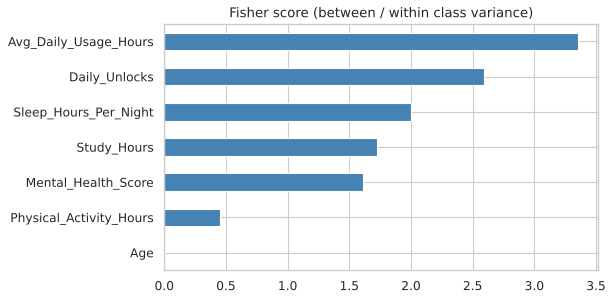

,Fisher score
Avg_Daily_Usage_Hours,3.350
Daily_Unlocks,2.592
Sleep_Hours_Per_Night,2.000
Study_Hours,1.724
Mental_Health_Score,1.612
Physical_Activity_Hours,0.454
Age,0.008


In [ ]:
# Fisher score per feature = between-class variance / within-class variance (higher = separates the classes better).
# Same idea as skfeature's fisher_score in the lecture example, written out with pandas so it runs without skfeature.
grp = df.groupby(TARGET, observed=True)[num_cols]
n_k = grp.size()
between = ((grp.mean() - df[num_cols].mean()) ** 2).mul(n_k, axis=0).sum()
within = grp.var(ddof=0).mul(n_k, axis=0).sum()
fisher = (between / within).sort_values()
fisher.plot.barh(
    figsize=(7, 4),
    color="steelblue",
    title="Fisher score (between / within class variance)",
)
plt.show()
display(fisher.sort_values(ascending=False).round(3).to_frame("Fisher score"))

## 2c) High cardinality

,unique,unique_%_of_rows,top_value_share_%,rare_levels(<1%)
Country,111,2.22,37.6,88
Most_Used_Platform,12,0.24,22.6,3
Purpose_Of_Use,4,0.08,51.0,0
Academic_Level,3,0.06,72.6,0
Gender,2,0.04,52.7,0


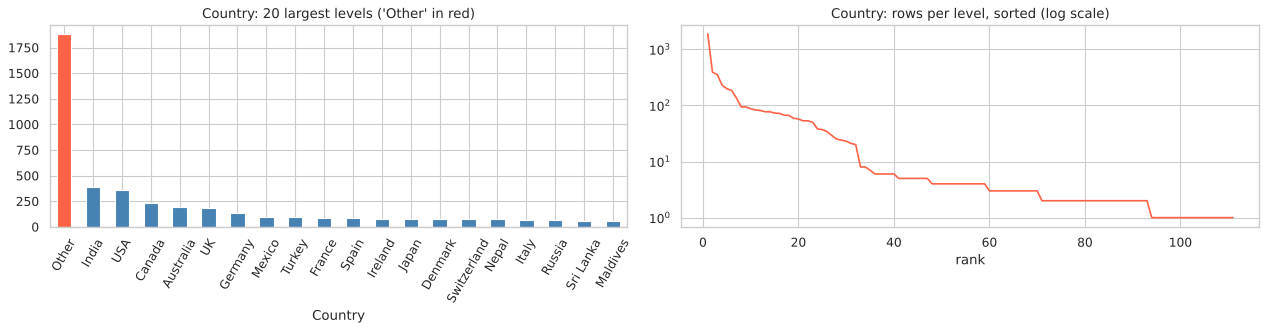

'Other': 1880 rows (37.6%) | countries with < 10 rows: 79 | with exactly 1 row: 18


In [ ]:
# Step 2c: cardinality
display(cardinality_table(df, cat_cols))
vc = df["Country"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.3))
vc.head(20).plot.bar(ax=ax[0], color=["tomato"] + ["steelblue"] * 19, rot=60)
ax[0].set_title("Country: 20 largest levels ('Other' in red)")
ax[1].plot(range(1, len(vc) + 1), vc.values, color="tomato")
ax[1].set_yscale("log")
ax[1].set_title("Country: rows per level, sorted (log scale)")
ax[1].set_xlabel("rank")
plt.tight_layout()
plt.show()
print(
    f"'Other': {vc['Other']} rows ({vc['Other'] / len(df):.1%}) | countries with < 10 rows: {(vc < 10).sum()} | with exactly 1 row: {(vc == 1).sum()}"
)

## 3a) Major trends

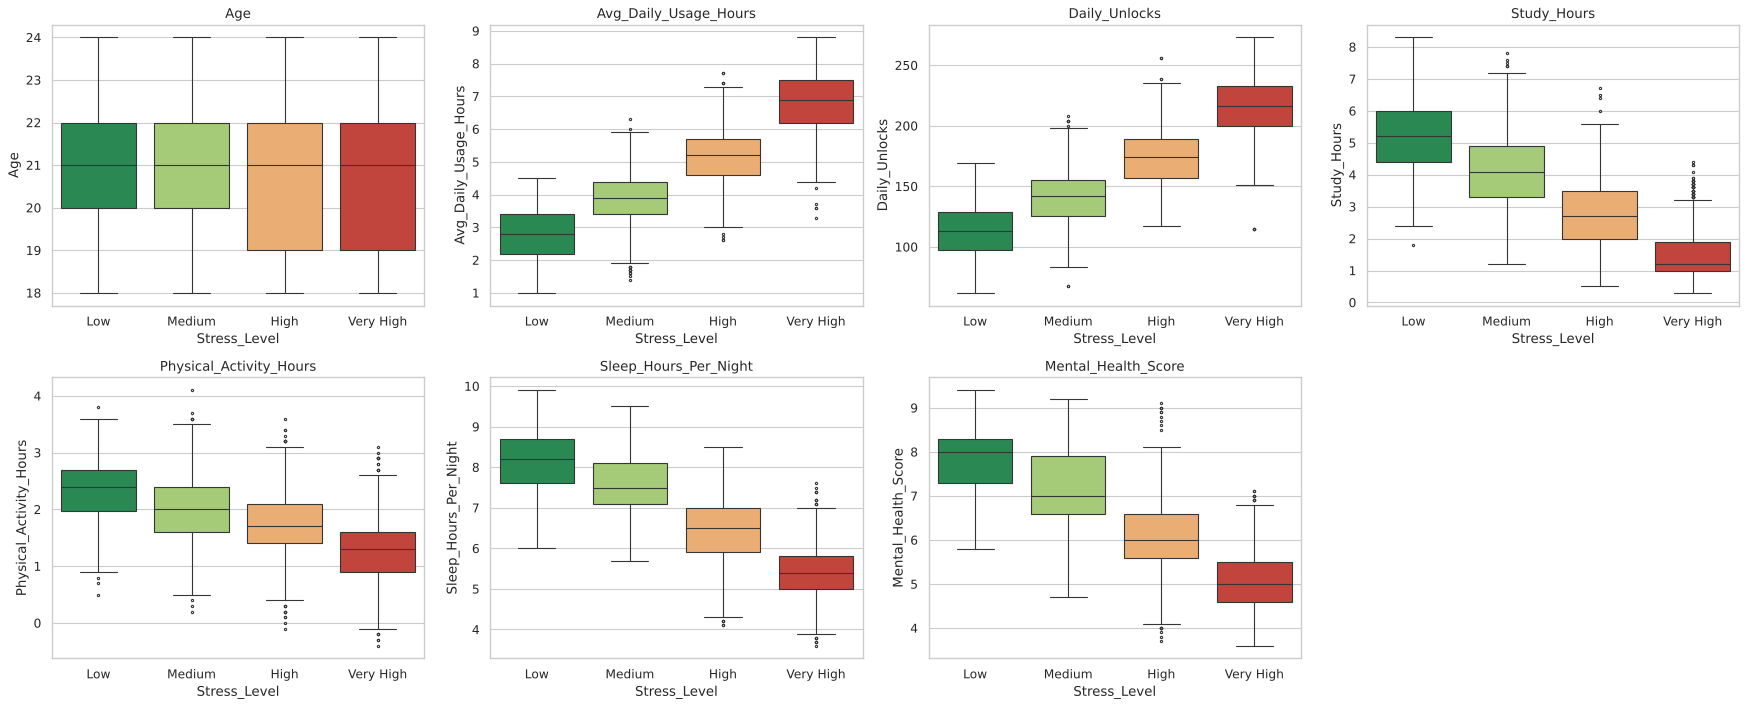

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
Stress_Level,,,,,,,
Low,21.04,2.78,113.82,5.18,2.35,8.16,7.84
Medium,21.00,3.86,141.01,4.12,2.05,7.57,7.14
High,20.70,5.19,173.98,2.75,1.73,6.45,6.03
Very High,20.70,6.87,216.42,1.49,1.29,5.44,5.05


In [ ]:
# Step 3a-1: numeric features vs stress
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(
        data=df, x=TARGET, y=col, order=ORDER, palette=PALETTE, ax=ax, fliersize=2
    )
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()
display(df.groupby(TARGET, observed=True)[num_cols].mean().round(2))

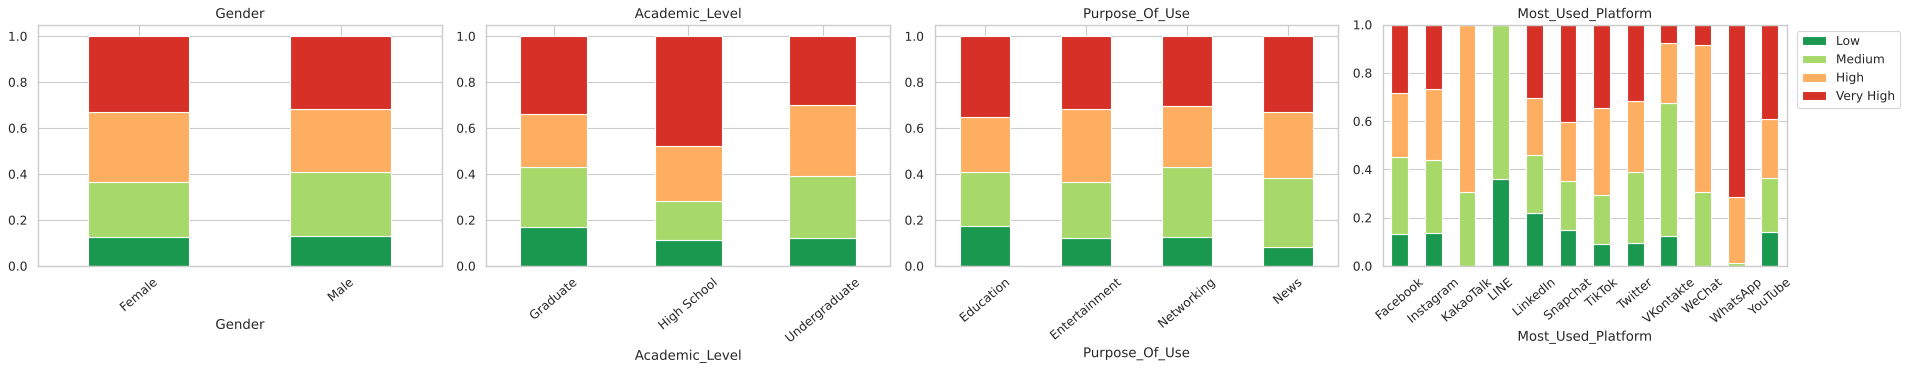

In [ ]:
# Step 3a-2: categorical features vs stress (share of each class inside each category)
fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
for ax, col in zip(
    axes, ["Gender", "Academic_Level", "Purpose_Of_Use", "Most_Used_Platform"]
):
    pd.crosstab(df[col], df[TARGET], normalize="index")[ORDER].plot.bar(
        stacked=True, ax=ax, color=PALETTE, rot=40, legend=False
    )
    ax.set_title(col)
axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

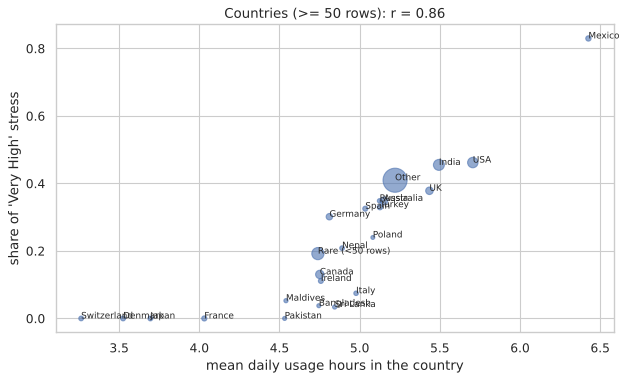

C,Denmark,France,Pakistan,Japan,Switzerland,Sri Lanka,Bangladesh,Maldives,Italy,Ireland,Canada,Rare (<50 rows),Nepal,Poland,Germany,Spain,Turkey,Russia,Australia,UK,Other,India,USA,Mexico
rows,77.00,87.00,53.00,77.00,73.00,59.00,53.00,57.00,67.00,81.00,230.00,484.00,72.00,50.00,136.00,83.00,94.00,66.00,198.00,185.00,1880.00,389.00,355.00,94.00
mean_usage,3.52,4.03,4.53,3.69,3.26,4.84,4.75,4.54,4.98,4.76,4.75,4.74,4.89,5.08,4.81,5.03,5.13,5.12,5.15,5.44,5.22,5.49,5.71,6.43
share_very_high,0.00,0.00,0.00,0.00,0.00,0.03,0.04,0.05,0.07,0.11,0.13,0.19,0.21,0.24,0.30,0.33,0.33,0.35,0.35,0.38,0.41,0.46,0.46,0.83


In [ ]:
# Step 3a-3: Country - surprisingly strong. Is it just a proxy for usage hours?
country = df["Country"].where(df["Country"].map(vc) >= 50, "Rare (<50 rows)")
g = (
    df.assign(C=country)
    .groupby("C")
    .agg(
        rows=(TARGET, "size"),
        mean_usage=("Avg_Daily_Usage_Hours", "mean"),
        share_very_high=(TARGET, lambda s: (s == "Very High").mean()),
    )
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(g["mean_usage"], g["share_very_high"], s=g["rows"] / 4, alpha=0.6)
for name, r in g.iterrows():
    ax.annotate(name, (r["mean_usage"], r["share_very_high"]), fontsize=8)
ax.set_xlabel("mean daily usage hours in the country")
ax.set_ylabel("share of 'Very High' stress")
ax.set_title(
    f"Countries (>= 50 rows): r = {np.corrcoef(g['mean_usage'], g['share_very_high'])[0, 1]:.2f}"
)
plt.show()
display(g.sort_values("share_very_high").round(2).T)

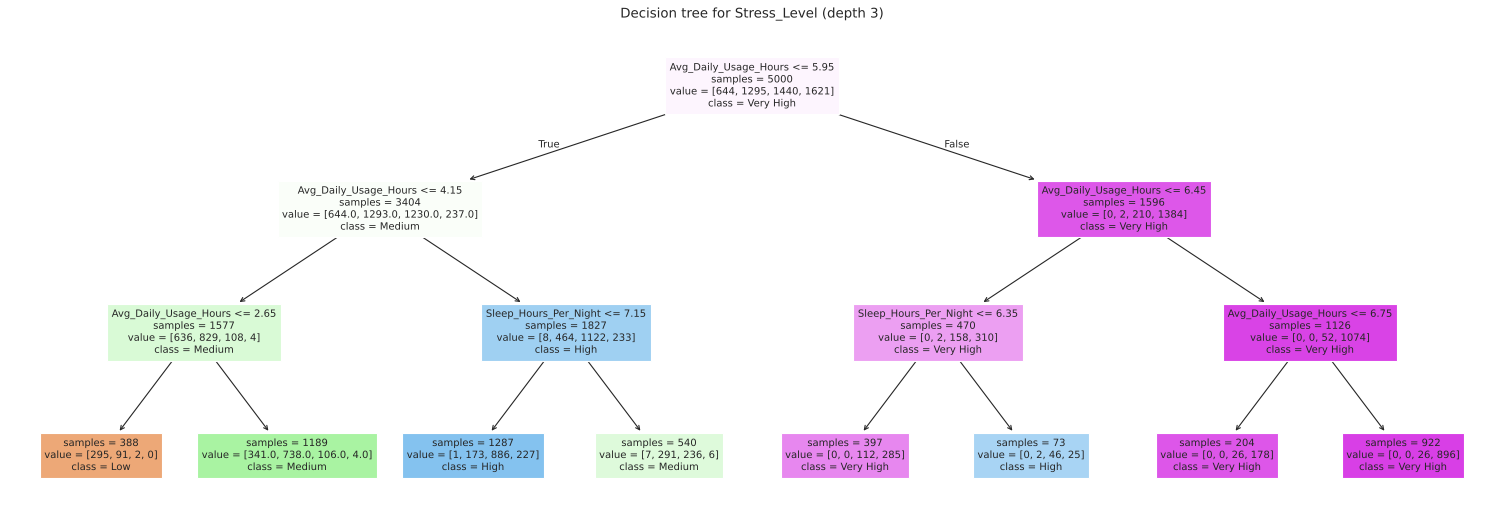

In [ ]:
# Decision tree (depth 3) - which variables does a tree split on first?
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(
    df[num_cols], y_code
)  # classes 0..3 = Low..Very High
plt.figure(figsize=(24, 8))
plot_tree(
    tree,
    feature_names=num_cols,
    class_names=ORDER,
    filled=True,
    impurity=False,
    fontsize=9,
)
plt.title("Decision tree for Stress_Level (depth 3)")
plt.show()

## 3b) Overlapping data

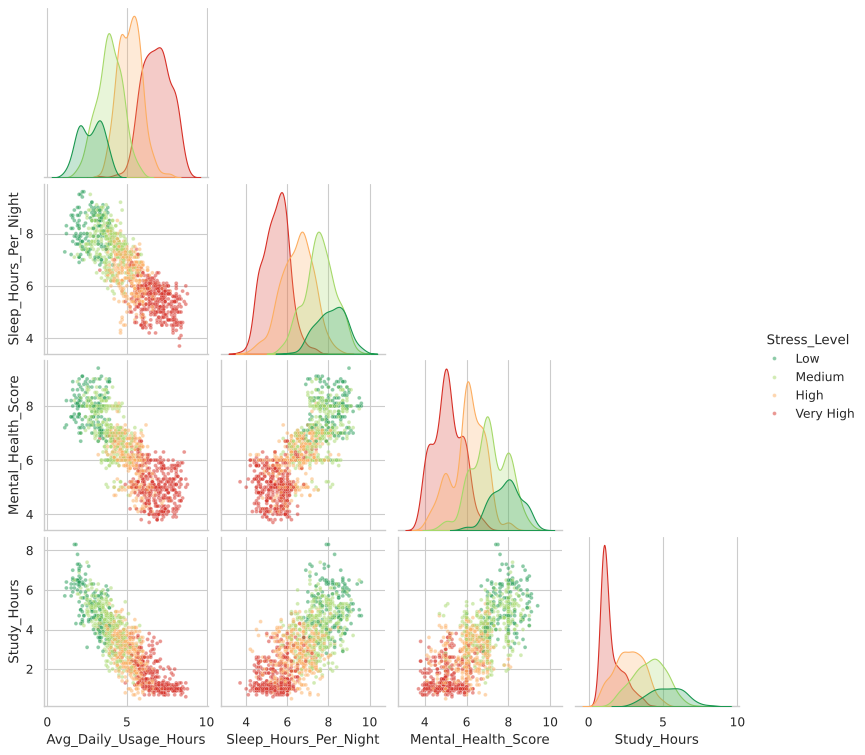

Stress_Level,Low,Medium,High,Very High
min,1.0,1.4,2.6,3.3
median,2.8,3.9,5.2,6.9
max,4.5,6.3,7.7,8.8


Stress_Level,Low,Medium,High,Very High
Avg_Daily_Usage_Hours,,,,
"(0, 2]",130,23,0,0
"(2, 3]",254,183,5,0
"(3, 4]",247,566,79,4
"(4, 5]",13,452,535,10
"(5, 6]",0,70,658,276
"(6, 7]",0,1,152,651
"(7, 9]",0,0,11,680


In [ ]:
# Step 3b-1: overlap between classes in the strongest features
sns.pairplot(
    df.sample(1200, random_state=1),
    vars=[
        "Avg_Daily_Usage_Hours",
        "Sleep_Hours_Per_Night",
        "Mental_Health_Score",
        "Study_Hours",
    ],
    hue=TARGET,
    hue_order=ORDER,
    palette=PALETTE,
    plot_kws={"alpha": 0.5, "s": 12},
    corner=True,
    height=2.4,
)
plt.show()
display(
    df.groupby(TARGET, observed=True)["Avg_Daily_Usage_Hours"]
    .agg(["min", "median", "max"])
    .T
)
bins = pd.cut(df["Avg_Daily_Usage_Hours"], [0, 2, 3, 4, 5, 6, 7, 9])
display(pd.crosstab(bins, df[TARGET])[ORDER])

In [ ]:
# Step 3b-2: where does a model confuse the classes? (random forest, 5-fold CV predictions)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf = RandomForestClassifier(300, random_state=42, n_jobs=-1)
pred = cross_val_predict(rf, df[num_cols], y_code, cv=cv)
cm = pd.DataFrame(
    confusion_matrix(y_code, pred),
    index=[f"true {c}" for c in ORDER],
    columns=[f"pred {c}" for c in ORDER],
)
display(cm)
off = np.abs(np.subtract.outer(range(4), range(4)))
print(
    f"Accuracy {np.trace(cm.values) / cm.values.sum():.3f} | errors to a NEIGHBOURING class: "
    f"{cm.values[off == 1].sum() / cm.values[off > 0].sum():.1%} of all errors | majority-class baseline {counts.max() / len(df):.3f}"
)

,pred Low,pred Medium,pred High,pred Very High
true Low,506,135,3,0
true Medium,73,1049,172,1
true High,5,139,1141,155
true Very High,0,7,129,1485


Accuracy 0.836 | errors to a NEIGHBOURING class: 98.0% of all errors | majority-class baseline 0.324


## 3c) Outliers and noise

,IQR_outliers,IQR_%,n_|z|>3,n_MAD_outliers,lower_fence,upper_fence,min,max
column,,,,,,,,
Age,0,0.00,0,0.0,14.50,26.50,18.0,24.0
Avg_Daily_Usage_Hours,0,0.00,0,0.0,0.05,10.05,1.0,8.8
Daily_Unlocks,0,0.00,0,0.0,44.00,300.00,62.0,273.0
Study_Hours,2,0.04,3,0.0,-2.55,8.25,0.3,8.3
Physical_Activity_Hours,22,0.44,5,0.0,-0.05,3.55,-0.4,4.1
Sleep_Hours_Per_Night,0,0.00,0,0.0,2.75,10.35,3.6,9.9
Mental_Health_Score,0,0.00,0,0.0,2.10,10.10,3.6,9.4


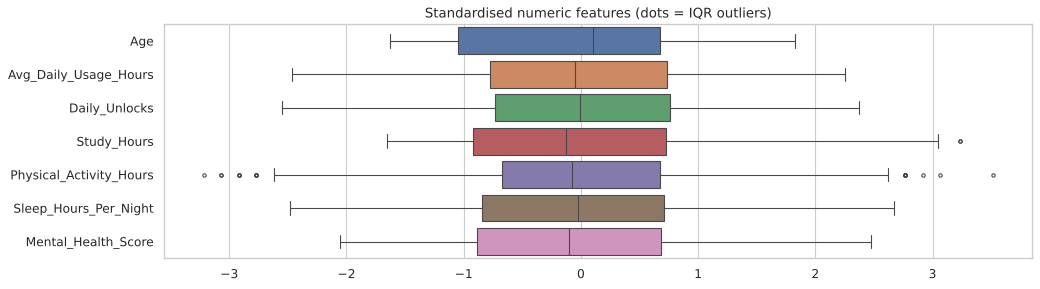

In [ ]:
# Step 3c-1: univariate outlier rules
res = (
    iqr_outliers(df, num_cols)
    .join(zscore_outliers(df, num_cols))
    .join(mad_outliers(df, num_cols))
)
display(
    res[
        [
            "n_outliers",
            "pct",
            "n_|z|>3",
            "n_MAD_outliers",
            "lower_fence",
            "upper_fence",
            "min",
            "max",
        ]
    ].rename(columns={"n_outliers": "IQR_outliers", "pct": "IQR_%"})
)
plt.figure(figsize=(14, 3.8))
sns.boxplot(
    data=(df[num_cols] - df[num_cols].mean()) / df[num_cols].std(),
    orient="h",
    fliersize=3,
)
plt.title("Standardised numeric features (dots = IQR outliers)")
plt.show()

In [ ]:
# Step 3c-2: multivariate outliers and noise
out = pd.DataFrame(
    {
        "isolation_forest": isolation_forest_flags(df, num_cols),
        "elliptic_envelope": elliptic_flags(df, num_cols),
    }
)
both = df[out.all(axis=1)]
print(out.sum().to_dict(), "| flagged by both:", len(both))
display(
    pd.DataFrame(
        {"flagged by both": both[num_cols].median(), "all rows": df[num_cols].median()}
    ).T.round(2)
)
print(
    "Stress level of rows flagged by both:",
    both[TARGET].value_counts().reindex(ORDER).to_dict(),
)
ratio = df["Daily_Unlocks"] / df["Avg_Daily_Usage_Hours"]
print(f"Unlocks per usage hour: median {ratio.median():.1f}, max {ratio.max():.1f}")
display(
    df.loc[ratio.nlargest(3).index, ["Avg_Daily_Usage_Hours", "Daily_Unlocks", TARGET]]
)

{'isolation_forest': 100, 'elliptic_envelope': 100} | flagged by both: 23


,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
flagged by both,22.0,2.0,102.0,7.1,3.1,7.4,8.4
all rows,21.0,5.0,171.0,2.8,1.7,6.6,6.1


Stress level of rows flagged by both: {'Low': 15, 'Medium': 7, 'High': 0, 'Very High': 1}
Unlocks per usage hour: median 33.8, max 73.0


,Avg_Daily_Usage_Hours,Daily_Unlocks,Stress_Level
2410,1.0,73,Low
3219,1.2,86,Low
4893,1.5,104,Low


## 3d) Correlations and associations

,Pearson,Spearman
Avg_Daily_Usage_Hours,0.873,0.890
Daily_Unlocks,0.845,0.861
Sleep_Hours_Per_Night,-0.811,-0.821
Study_Hours,-0.795,-0.800
Mental_Health_Score,-0.783,-0.792
Physical_Activity_Hours,-0.556,-0.560
Age,-0.078,-0.079


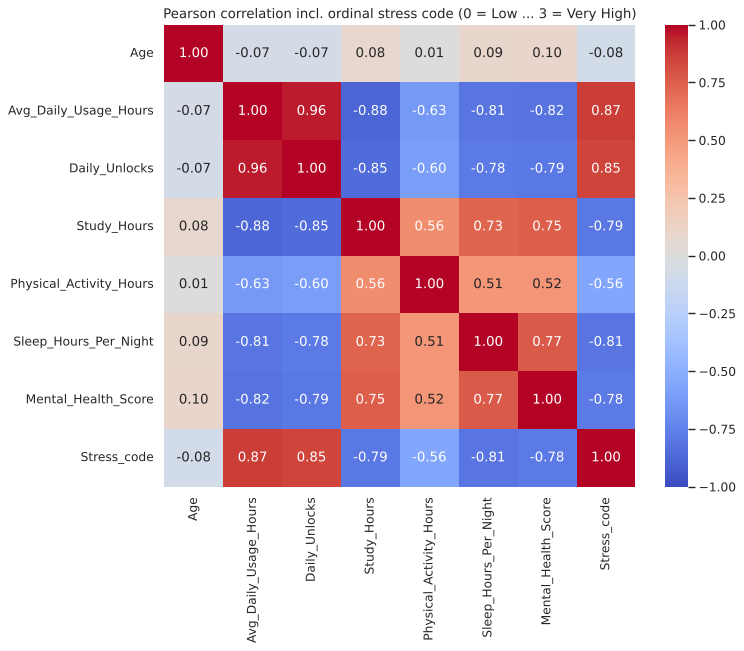

In [ ]:
# Step 3d-1: linear (Pearson) and rank (Spearman) correlation with the ordinal stress code
cmp = pd.DataFrame(
    {
        "Pearson": df[num_cols].corrwith(y_code),
        "Spearman": df[num_cols].corrwith(y_code, method="spearman"),
    }
)
display(cmp.sort_values("Pearson", key=abs, ascending=False).round(3))
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    df[num_cols].assign(Stress_code=y_code).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
)
ax.set_title(
    "Pearson correlation incl. ordinal stress code (0 = Low ... 3 = Very High)"
)
plt.show()

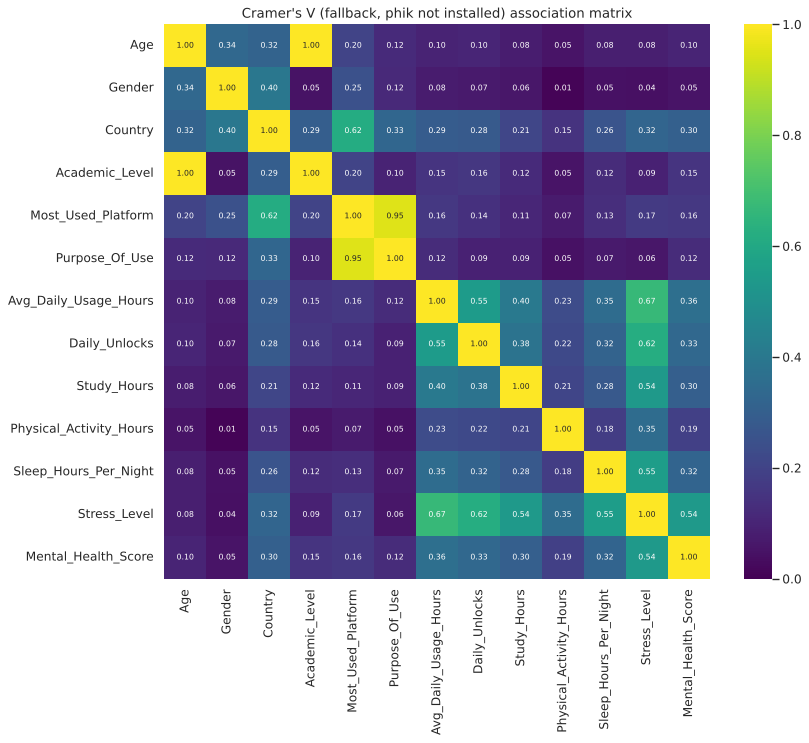

,"Cramer's V (fallback, phik not installed) with Stress_Level"
Avg_Daily_Usage_Hours,0.668
Daily_Unlocks,0.619
Sleep_Hours_Per_Night,0.553
Mental_Health_Score,0.538
Study_Hours,0.537
Physical_Activity_Hours,0.351
Country,0.324
Most_Used_Platform,0.169
Academic_Level,0.091
Age,0.084


In [ ]:
# Step 3d-2: Phi-K (falls back to Cramer's V if phik is missing)
pk, method = association_matrix(df, interval_cols=num_cols)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    pk,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    annot_kws={"size": 7},
    ax=ax,
)
ax.set_title(f"{method} association matrix")
plt.show()
display(
    pk[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
    .round(3)
    .to_frame(f"{method} with {TARGET}")
)

In [ ]:
# Step 3d-3: chi-square test of the categorical features with the target (Country with rare levels grouped)
rows = {}
for col, s in {
    "Country (111 levels)": df["Country"],
    "Country (rare grouped, 24 levels)": country,
    "Most_Used_Platform": df["Most_Used_Platform"],
    "Academic_Level": df["Academic_Level"],
    "Purpose_Of_Use": df["Purpose_Of_Use"],
    "Gender": df["Gender"],
}.items():
    ct = pd.crosstab(s, df[TARGET])
    r = stats.chi2_contingency(ct)
    rows[col] = {
        "p-value": r.pvalue,
        "Cramer's V": np.sqrt(r.statistic / (ct.values.sum() * (min(ct.shape) - 1))),
        "% cells expected < 5": (r.expected_freq < 5).mean() * 100,
    }
display(pd.DataFrame(rows).T.round({"Cramer's V": 3, "% cells expected < 5": 1}))

,p-value,Cramer's V,% cells expected < 5
Country (111 levels),2.406543e-219,0.356,73.2
"Country (rare grouped, 24 levels)",4.610624e-191,0.274,0.0
Most_Used_Platform,8.081091e-77,0.175,4.2
Academic_Level,4.438557e-17,0.094,0.0
Purpose_Of_Use,2.164743e-10,0.065,0.0
Gender,7.295975e-03,0.049,0.0


In [ ]:
DF_DY = df
# Dython associations - same settings as the lecture example (dython_associations_example.ipynb)
try:
    from dython.nominal import associations

    assoc = associations(
        DF_DY,
        nominal_columns="auto",
        nom_nom_assoc="theil",
        num_num_assoc="pearson",
        nom_num_assoc="correlation_ratio",
        plot=False,
    )
    a = (
        pd.DataFrame(assoc["corr"])[[TARGET]]
        .drop(TARGET)
        .sort_values(TARGET, ascending=False)
    )
    plt.figure(figsize=(4, 7))
    sns.heatmap(a, annot=True, fmt=".2f", cmap="viridis")
    plt.title(f"Dython associations with {TARGET}")
    plt.show()
except Exception as e:
    print(f"Dython skipped: {type(e).__name__}: {e}")

Dython skipped: ModuleNotFoundError: No module named 'dython'


## 3e) Feature importance

Left out (too many levels): ['Country'] | matrix: (5000, 28)


,ANOVA_F,mutual_info,RF_impurity,RF_permutation (held-out),"RFE_rank (logistic, top 5 = 1)"
Avg_Daily_Usage_Hours,5579.598,0.723,0.208,0.148,1
Sleep_Hours_Per_Night,3330.803,0.529,0.148,0.112,1
Daily_Unlocks,4316.536,0.678,0.188,0.097,1
Mental_Health_Score,2685.017,0.486,0.117,0.062,2
Study_Hours,2870.741,0.467,0.109,0.054,8
Physical_Activity_Hours,756.253,0.193,0.075,0.031,18
Age,12.597,0.014,0.035,0.029,12
Gender_Male,4.015,0.000,0.011,0.017,19
Gender_Female,4.015,0.013,0.010,0.012,22
Academic_Level_Undergraduate,17.714,0.005,0.008,0.012,23


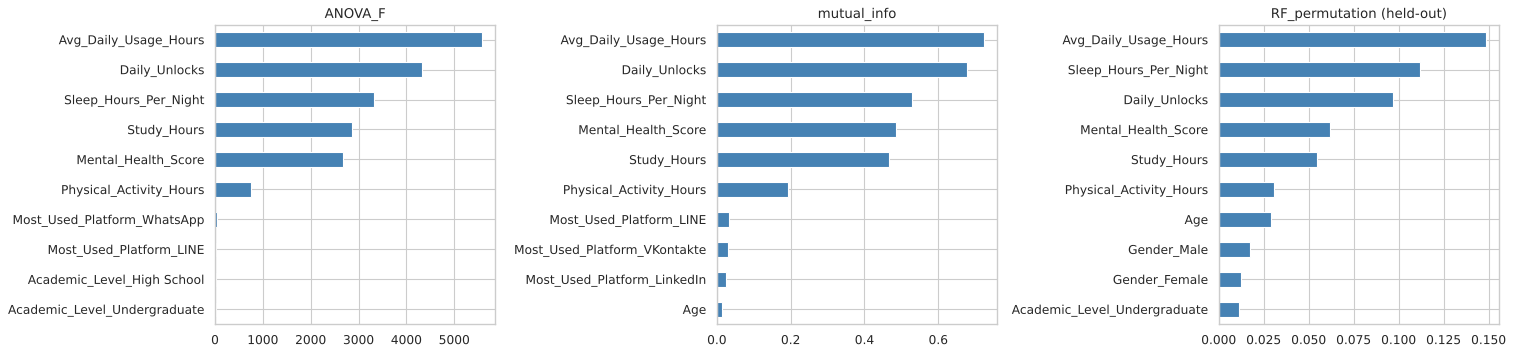

In [ ]:
# Step 3e: feature importance from five angles
from sklearn.feature_selection import f_classif, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X, y, dropped = make_model_matrix(df, TARGET)
y = y.cat.codes
print("Left out (too many levels):", dropped, "| matrix:", X.shape)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
rf_fit = RandomForestClassifier(300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
imp = pd.DataFrame(
    {
        "ANOVA_F": f_classif(X, y)[0],
        "mutual_info": mutual_info_classif(X, y, random_state=42),
        "RF_impurity": rf_fit.feature_importances_,
        "RF_permutation (held-out)": permutation_importance(
            rf_fit, Xte, yte, n_repeats=10, random_state=0, n_jobs=-1
        ).importances_mean,
    },
    index=X.columns,
)
imp["RFE_rank (logistic, top 5 = 1)"] = (
    RFE(LogisticRegression(max_iter=3000), n_features_to_select=5)
    .fit(StandardScaler().fit_transform(X), y)
    .ranking_
)
display(imp.sort_values("RF_permutation (held-out)", ascending=False).round(3).head(12))
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
for a, col in zip(ax, ["ANOVA_F", "mutual_info", "RF_permutation (held-out)"]):
    imp[col].sort_values().tail(10).plot.barh(ax=a, color="steelblue")
    a.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
# Step 3e-2: what happens to accuracy when features are removed / added? (5-fold CV random forest)
sets = {
    "all 7 numeric": num_cols,
    "without Mental_Health_Score": [c for c in num_cols if c != "Mental_Health_Score"],
    "without Daily_Unlocks": [c for c in num_cols if c != "Daily_Unlocks"],
    "without Age": [c for c in num_cols if c != "Age"],
    "usage + sleep + study only": [
        "Avg_Daily_Usage_Hours",
        "Sleep_Hours_Per_Night",
        "Study_Hours",
    ],
}
acc = {k: cross_val_score(rf, df[v], y_code, cv=cv).mean() for k, v in sets.items()}
acc["all 7 numeric + Country (grouped)"] = cross_val_score(
    rf,
    pd.concat([df[num_cols], pd.get_dummies(country, dtype=float)], axis=1),
    y_code,
    cv=cv,
).mean()
display(pd.Series(acc).round(3).to_frame("5-fold CV accuracy"))

,5-fold CV accuracy
all 7 numeric,0.836
without Mental_Health_Score,0.841
without Daily_Unlocks,0.790
without Age,0.819
usage + sleep + study only,0.715
all 7 numeric + Country (grouped),0.867


## 4a) Rare combinations

In [ ]:
# Step 4a: rare combinations
combo = (
    df.groupby(["Academic_Level", "Most_Used_Platform", "Purpose_Of_Use"])
    .size()
    .sort_values()
)
print(
    f"{len(combo)} of {3 * 12 * 4} possible Academic_Level x Platform x Purpose combinations occur; {(combo <= 5).sum()} have 5 rows or fewer"
)
display(combo.head(8).to_frame("rows"))
print(
    "Low stress AND > 6 h daily usage:",
    int(((df[TARGET] == "Low") & (df.Avg_Daily_Usage_Hours > 6)).sum()),
    "| Very High stress AND < 3 h usage:",
    int(((df[TARGET] == "Very High") & (df.Avg_Daily_Usage_Hours < 3)).sum()),
)
try:
    from mlxtend.frequent_patterns import apriori

    basket = pd.get_dummies(
        df[["Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Gender"]]
    ).astype(bool)
    freq = apriori(basket, min_support=0.002, use_colnames=True)
    freq["size"] = freq["itemsets"].apply(len)
    display(freq[freq["size"] >= 3].sort_values("support").head(8))
except Exception as e:
    print(f"Apriori (mlxtend) skipped: {type(e).__name__}: {e}")

44 of 144 possible Academic_Level x Platform x Purpose combinations occur; 5 have 5 rows or fewer


rows
Academic_Level Most_Used_Platform Purpose_Of_Use      
Graduate       WeChat             Networking         1
                                  Entertainment      2
                                  News               2
Undergraduate  WeChat             Networking         3
               KakaoTalk          Education          5
               VKontakte          Education          6
               WeChat             Entertainment      7
                                  Education          8

Low stress AND > 6 h daily usage: 0 | Very High stress AND < 3 h usage: 0
Apriori (mlxtend) skipped: ModuleNotFoundError: No module named 'mlxtend'


## 4b) Derived features

In [ ]:
# Step 4b: derived features - do they separate the classes better than the originals?
d = df.copy()
d["sleep_minus_usage"] = d["Sleep_Hours_Per_Night"] - d["Avg_Daily_Usage_Hours"]
d["usage_to_sleep"] = d["Avg_Daily_Usage_Hours"] / d["Sleep_Hours_Per_Night"]
d["unlocks_per_hour"] = d["Daily_Unlocks"] / d["Avg_Daily_Usage_Hours"]
d["usage_share_of_awake_time"] = d["Avg_Daily_Usage_Hours"] / (
    24 - d["Sleep_Hours_Per_Night"]
)
d["screen_minus_study"] = d["Avg_Daily_Usage_Hours"] - d["Study_Hours"]
new = [
    "sleep_minus_usage",
    "usage_to_sleep",
    "unlocks_per_hour",
    "usage_share_of_awake_time",
    "screen_minus_study",
]
cols = num_cols + new
F = pd.DataFrame(
    {
        "ANOVA F": f_classif(d[cols], y_code)[0],
        "Spearman with stress": d[cols].corrwith(y_code, method="spearman"),
    },
    index=cols,
)
F["new?"] = ["new" if c in new else "" for c in cols]
display(F.sort_values("ANOVA F", ascending=False).round(3))
acc_new = cross_val_score(
    rf, d[num_cols + ["sleep_minus_usage", "screen_minus_study"]], y_code, cv=cv
).mean()
print(
    f"RF accuracy with the 7 numeric features: {acc['all 7 numeric']:.3f} | + 2 derived features: {acc_new:.3f}"
)

,ANOVA F,Spearman with stress,new?
sleep_minus_usage,6615.378,-0.897,new
usage_to_sleep,5656.770,0.898,new
Avg_Daily_Usage_Hours,5579.598,0.890,
screen_minus_study,4843.877,0.869,new
Daily_Unlocks,4316.536,0.861,
usage_share_of_awake_time,4124.848,0.860,new
Sleep_Hours_Per_Night,3330.803,-0.821,
Study_Hours,2870.741,-0.800,
Mental_Health_Score,2685.017,-0.792,
unlocks_per_hour,1253.494,-0.659,new


RF accuracy with the 7 numeric features: 0.836 | + 2 derived features: 0.821


## 4c) Trends between support features

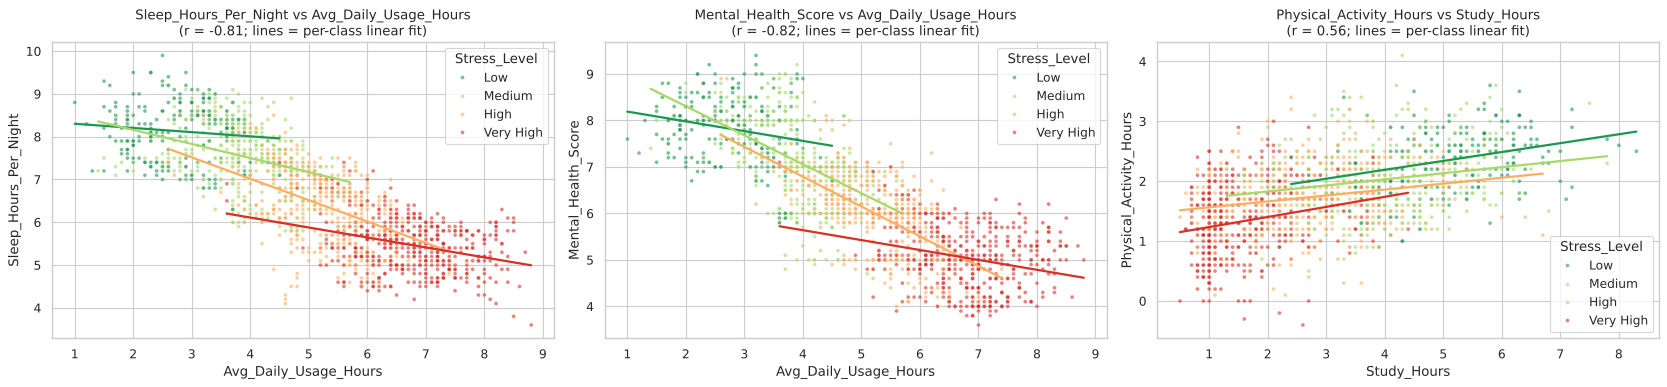

Usage vs sleep correlation INSIDE each stress class: {'Low': -0.08, 'Medium': -0.32, 'High': -0.47, 'Very High': -0.35}


In [ ]:
# Step 4c: trends between support features, coloured by stress
s = df.sample(1500, random_state=3)
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, (x, y_) in zip(
    axes,
    [
        ("Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"),
        ("Avg_Daily_Usage_Hours", "Mental_Health_Score"),
        ("Study_Hours", "Physical_Activity_Hours"),
    ],
):
    sns.scatterplot(
        data=s,
        x=x,
        y=y_,
        hue=TARGET,
        hue_order=ORDER,
        palette=PALETTE,
        s=12,
        alpha=0.6,
        ax=ax,
    )
    for lvl in ORDER:
        sub = s[s[TARGET] == lvl]
        k = np.polyfit(sub[x], sub[y_], 1)
        xs = np.linspace(sub[x].min(), sub[x].max(), 10)
        ax.plot(xs, np.polyval(k, xs), color=PALETTE[lvl], lw=2)
    ax.set_title(
        f"{y_} vs {x}\n(r = {df[x].corr(df[y_]):.2f}; lines = per-class linear fit)"
    )
plt.tight_layout()
plt.show()
within = {
    lvl: round(
        float(
            df.loc[df[TARGET] == lvl, "Avg_Daily_Usage_Hours"].corr(
                df.loc[df[TARGET] == lvl, "Sleep_Hours_Per_Night"]
            )
        ),
        2,
    )
    for lvl in ORDER
}
print("Usage vs sleep correlation INSIDE each stress class:", within)

## 4d) Conventional EDA vs tools

In [ ]:
# Step 4d: conventional pandas checks vs the tools' numbers
def ydata_says(col, alert):
    hit = yd[(yd.column == col) & (yd.alert == alert)]
    return hit["detail"].iloc[0] if len(hit) else "no alert"


check = pd.DataFrame(
    [
        (
            "Duplicate rows",
            f"{df.duplicated().sum()}",
            ydata_says("<whole table>", "DUPLICATES"),
        ),
        (
            "Missing cells",
            f"{df.isna().sum().sum()}",
            "no alert" if not (yd.alert == "MISSING").any() else "MISSING alert",
        ),
        (
            "Country distinct values",
            f"{df.Country.nunique()}",
            ydata_says("Country", "HIGH CARDINALITY"),
        ),
        (
            "Usage ~ Unlocks",
            f"Pearson {df.Avg_Daily_Usage_Hours.corr(df.Daily_Unlocks):.2f}",
            ydata_says("Avg_Daily_Usage_Hours", "HIGH CORRELATION"),
        ),
        (
            "Zeros in Physical_Activity_Hours",
            f"{(df.Physical_Activity_Hours == 0).sum()} ({(df.Physical_Activity_Hours == 0).mean():.2%})",
            ydata_says("Physical_Activity_Hours", "ZEROS"),
        ),
        ("NEGATIVE Physical_Activity_Hours", f"{neg.sum()}", "no rule exists for this"),
        (
            "Target imbalance",
            f"largest/smallest = {counts.max() / counts.min():.2f}",
            ydata_says(TARGET, "IMBALANCE"),
        ),
    ],
    columns=["check", "pandas (manual)", "ydata-style rule"],
)
display(check)
assert df.duplicated().sum() == 2 and df.isna().sum().sum() == 0
assert (df.Physical_Activity_Hours == 0).sum() == column_report(df).loc[
    "Physical_Activity_Hours", "zeros"
]
print("Manual counts agree with column_report() and the ydata-style rules.")

,check,pandas (manual),ydata-style rule
0,Duplicate rows,2,2 duplicate rows
1,Missing cells,0,no alert
2,Country distinct values,111,111 distinct values
3,Usage ~ Unlocks,Pearson 0.96,with Daily_Unlocks (Spearman 0.96)
4,Zeros in Physical_Activity_Hours,13 (0.26%),no alert
5,NEGATIVE Physical_Activity_Hours,10,no rule exists for this
6,Target imbalance,largest/smallest = 2.52,no alert


Manual counts agree with column_report() and the ydata-style rules.


## 4e) Polynomial trends

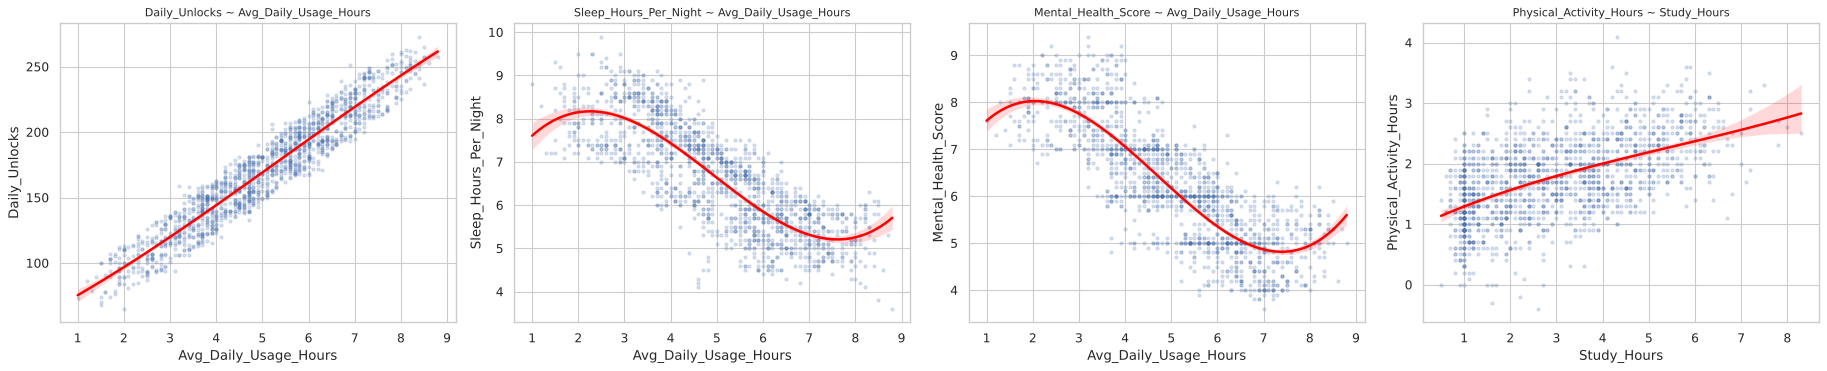

,degree 1,degree 2,degree 3
Daily_Unlocks ~ Avg_Daily_Usage_Hours,0.922,0.922,0.922
Sleep_Hours_Per_Night ~ Avg_Daily_Usage_Hours,0.653,0.654,0.684
Mental_Health_Score ~ Avg_Daily_Usage_Hours,0.667,0.679,0.713
Physical_Activity_Hours ~ Study_Hours,0.314,0.315,0.316


In [ ]:
# Step 4e: polynomial trends between the most connected pairs
pairs = [
    ("Avg_Daily_Usage_Hours", "Daily_Unlocks"),
    ("Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"),
    ("Avg_Daily_Usage_Hours", "Mental_Health_Score"),
    ("Study_Hours", "Physical_Activity_Hours"),
]
fig, axes = plt.subplots(1, 4, figsize=(23, 4.8))
rows = {}
for ax, (x, y_) in zip(axes, pairs):
    sns.regplot(
        data=s,
        x=x,
        y=y_,
        order=3,
        scatter_kws={"alpha": 0.2, "s": 8},
        line_kws={"color": "red"},
        ax=ax,
    )
    rows[f"{y_} ~ {x}"] = poly_r2(df[x].to_numpy(float), df[y_].to_numpy(float))
    ax.set_title(f"{y_} ~ {x}", fontsize=10)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).T)